# 04 — Feature Engineering and Compound-Risk Labels
Full definition: `docs/label_definition.md`.

**Physical features** (from observed T, RH):
* Dew point (Magnus): $T_d = \frac{b\,\gamma}{a-\gamma},\ \gamma=\ln(RH/100)+\frac{aT}{b+T},\ a=17.27,\ b=237.3$
* Saturation vapour pressure $e_s(T)=0.6108\,e^{17.27T/(T+237.3)}$ kPa; **VPD** $=e_s(T)(1-RH/100)$
* **Heat index** — NWS Rothfusz regression (with adjustments) where $(HI_{simple}+T)/2\ge 80^\circ$F, Steadman simple formula otherwise
* **Wet-bulb temperature** — Stull (2011) empirical formula
* Temperature anomaly vs Berkeley 1961–1990 calendar-month normal
* Past-only precipitation persistence: 7/30-day sums, wet-day fractions, days since recorded precipitation

**Hazard scores** $H, A, D \in \{0,1,2,3\}$ (NWS heat-index categories + wet-bulb; WHO 2021 air-quality
guideline/interim targets; VPD bands + 30-day dry-spell). **Compound class** with
$S = H + A + D$, $m=\max$, $n_2=\#\{\ge2\}$:

| Class | Rule |
|---|---|
| Critical | $S\ge6$ or ($m=3$ and $n_2\ge2$) |
| High | $S\ge4$ or $m=3$ or $n_2\ge2$ |
| Moderate | $S\ge2$ or $m\ge2$ |
| Low | otherwise |

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
from climatesense.utils import read_json
import platform, torch, sklearn
print("Executed:", pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "| Python", platform.python_version(),
      "| torch", torch.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)
def show(p, width=850):
    display(Image(filename=str(ROOT / p), width=width))

Executed: 2026-10-25 18:06 | Python 3.13.7 | torch 2.14.1+cu126 | sklearn 1.9.1 | pandas 3.1.0


In [2]:
from climatesense.features.engineering import heat_index_c, wet_bulb_stull_c, vpd_kpa, CLIMATE_FEATURES, AIR_FEATURES, DRY_FEATURES, CONTEXT_FEATURES
# sanity checks against published reference values
print("HI(90F, 60%) =", round(heat_index_c((90-32)*5/9, 60)*9/5+32, 1), "F  (NWS table: 100 F)")
print("Tw(20C, 50%) =", round(float(wet_bulb_stull_c(20.0, 50.0)), 2), "C  (Stull 2011: 13.7 C)")
print("VPD(30C, 40%) =", round(float(vpd_kpa(30.0, 40.0)), 2), "kPa")
pd.DataFrame({"climate": pd.Series(CLIMATE_FEATURES), "air": pd.Series(AIR_FEATURES), "dryness": pd.Series(DRY_FEATURES), "context": pd.Series(CONTEXT_FEATURES)}).fillna("")

HI(90F, 60%) = 99.7 F  (NWS table: 100 F)
Tw(20C, 50%) = 13.7 C  (Stull 2011: 13.7 C)
VPD(30C, 40%) = 2.55 kPa


,climate,air,dryness,context
0,temp_c,log_co,vpd_kpa,lat_scaled
1,feels_like_c,log_o3,log_precip,abs_lat_scaled
2,rh,log_no2,wet_flag,lon_sin
3,dewpoint_c,log_so2,precip_sum_7d,lon_cos
4,heat_index_c,log_pm25,precip_sum_30d,log_population
5,wet_bulb_c,log_pm10,wet_frac_7d,bk_normal_annual
6,wind_kph,us_epa_index,wet_frac_30d,bk_seasonal_amplitude
7,gust_kph,gb_defra_index,days_since_wet,bk_warming_recent_minus_normal
8,pressure_hpa,air_score,dry_score,
9,cloud,,,


### Label distribution and hazard composition

,Low,Moderate,High,Critical,total
test,14787,5105,2233,1810,23935
train,53553,31358,15316,12205,112432
val,15684,4992,1810,1643,24129


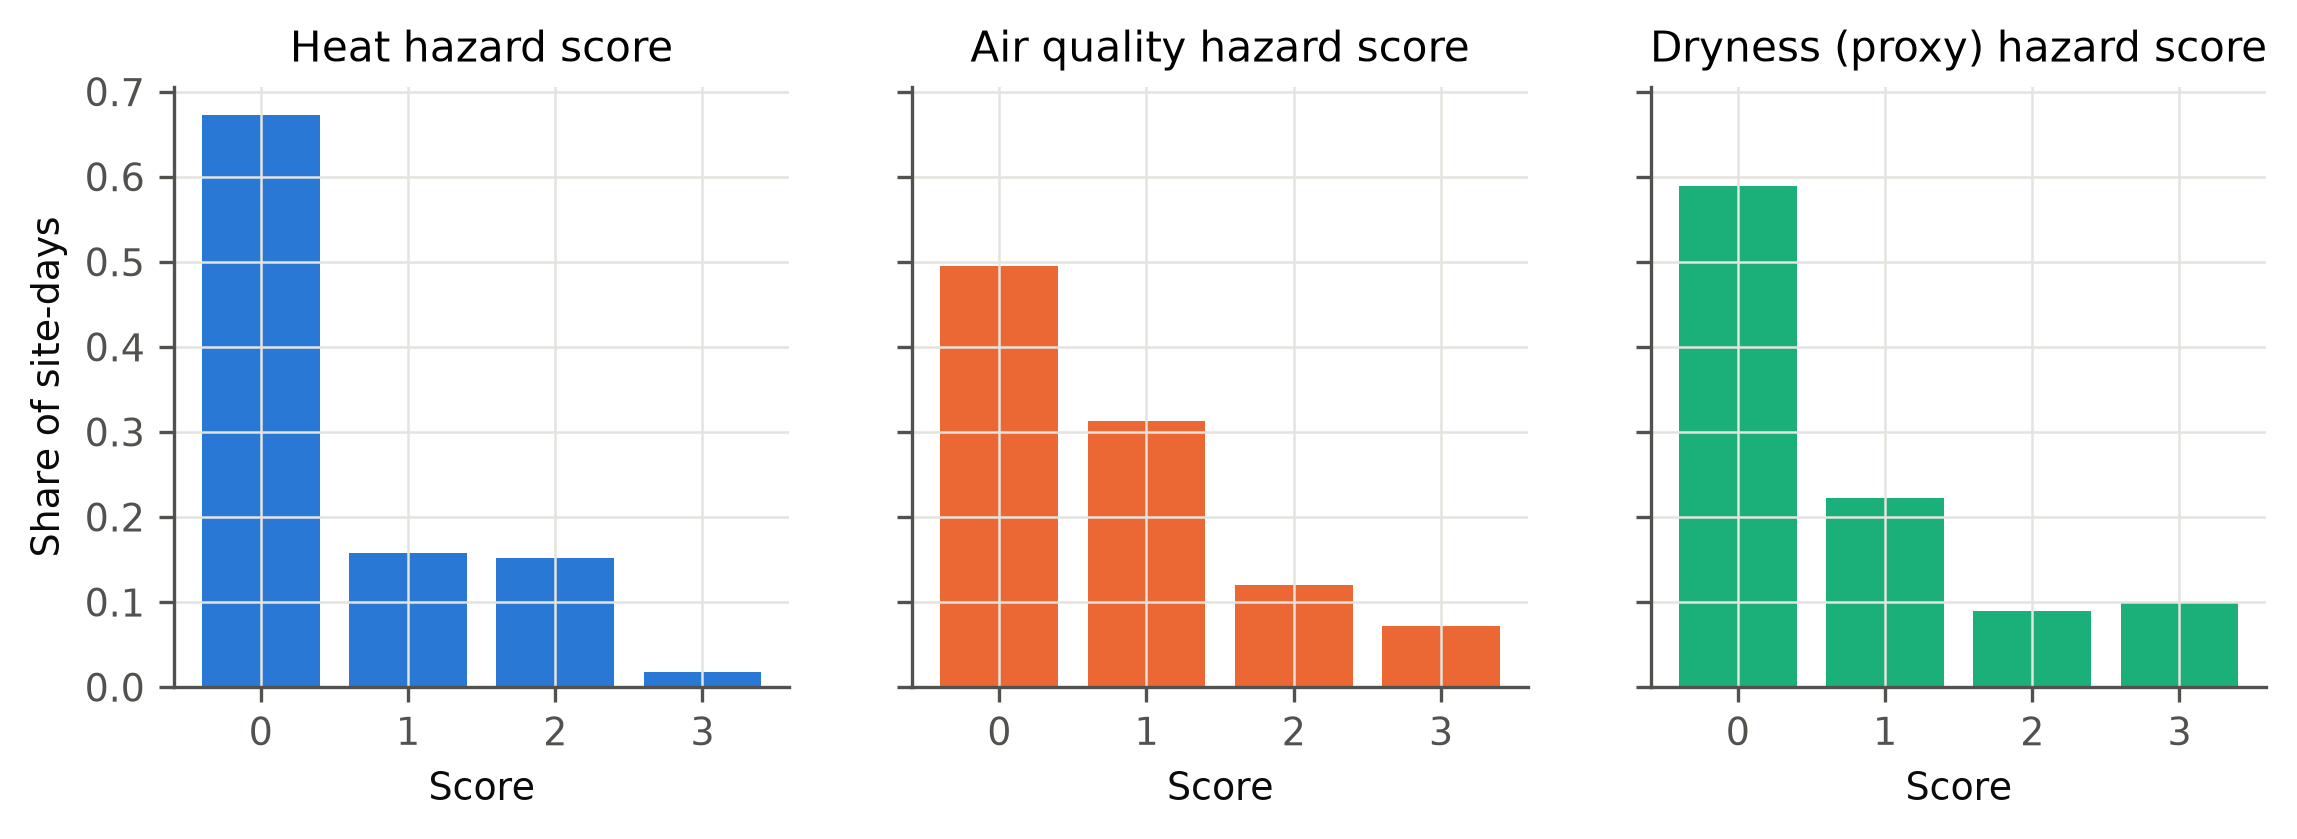

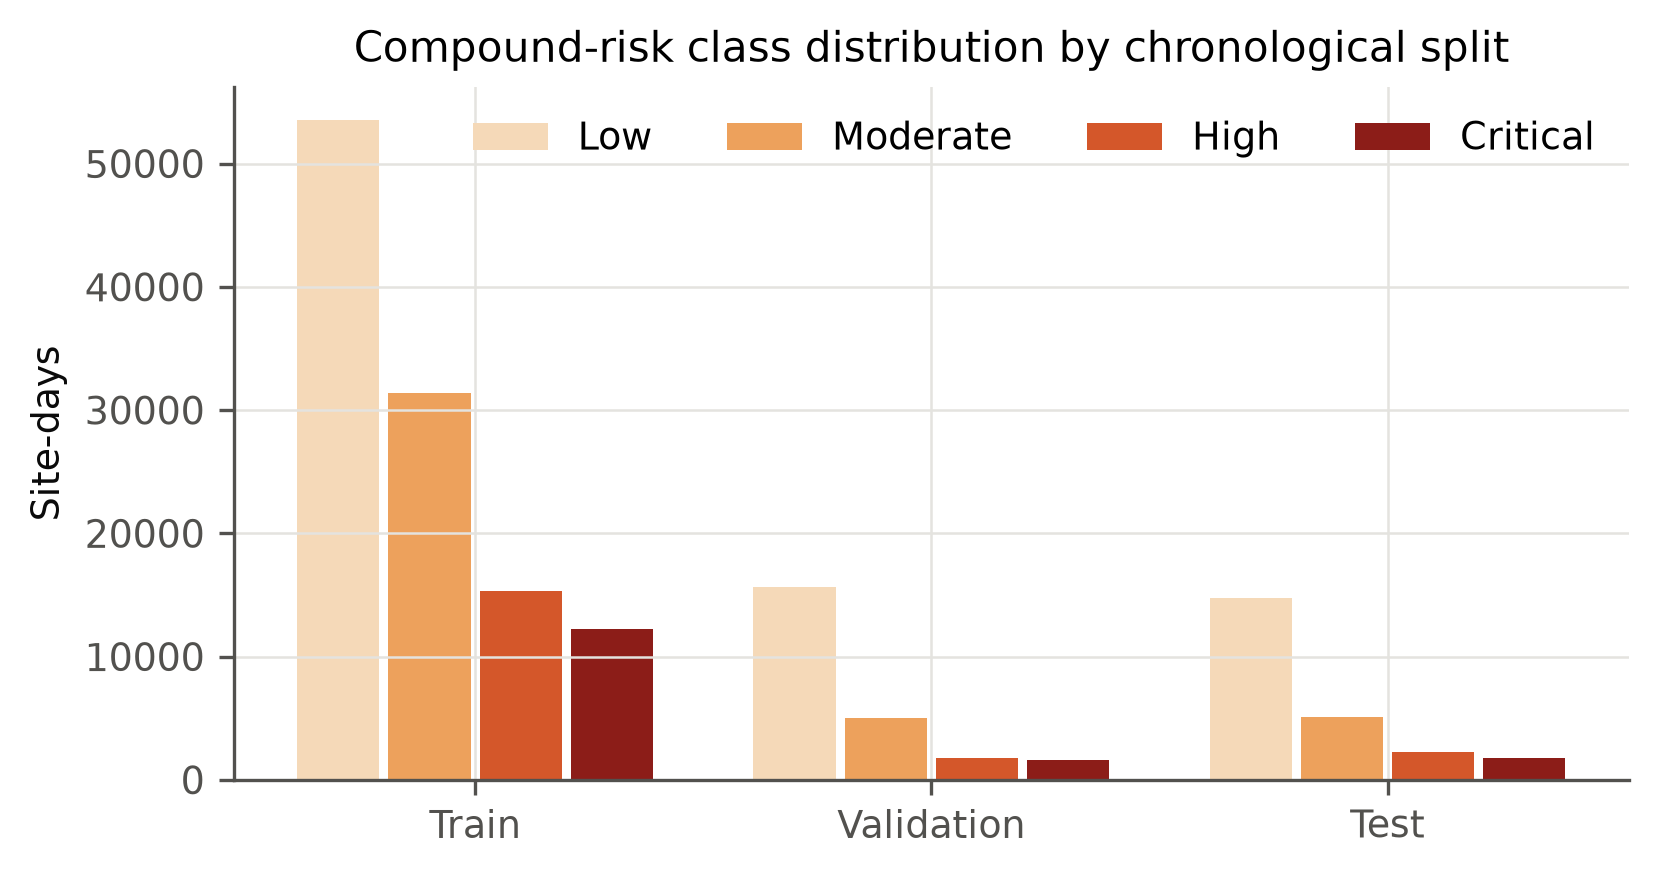

In [3]:
a = read_json(ROOT / "data/manifests/data_audit.json")
display(pd.DataFrame(a["label_distribution_by_split"]).T[["Low","Moderate","High","Critical"]].assign(total=lambda d: d.sum(1)))
show("results/figures/labels/hazard_scores.png"); show("results/figures/eda/class_distribution_by_split.png", 600)

### Sensitivity and validity analysis (computed before any model training)

In [4]:
ls = read_json(ROOT / "results/analysis/label_sensitivity.json")
pd.DataFrame({k: dict(kappa_w=v["quadratic_kappa_vs_base"], agreement=v["agreement_with_base"], **v["distribution"]) for k, v in ls["variants"].items()}).T.round(3)

,kappa_w,agreement,Low,Moderate,High,Critical
class_boundaries_-1,0.823,0.631,0.281,0.410,0.176,0.133
class_boundaries_+1,0.942,0.886,0.602,0.211,0.095,0.092
without_dryness,0.770,0.751,0.637,0.255,0.080,0.028
without_air,0.792,0.746,0.680,0.193,0.073,0.053
air_from_us_epa_index,0.878,0.791,0.640,0.210,0.082,0.068
heat_index_bands_-1C,0.979,0.959,0.498,0.275,0.123,0.104
heat_index_bands_+1C,0.986,0.973,0.537,0.253,0.118,0.092
vpd_bands_x1.25,0.965,0.932,0.552,0.254,0.111,0.083


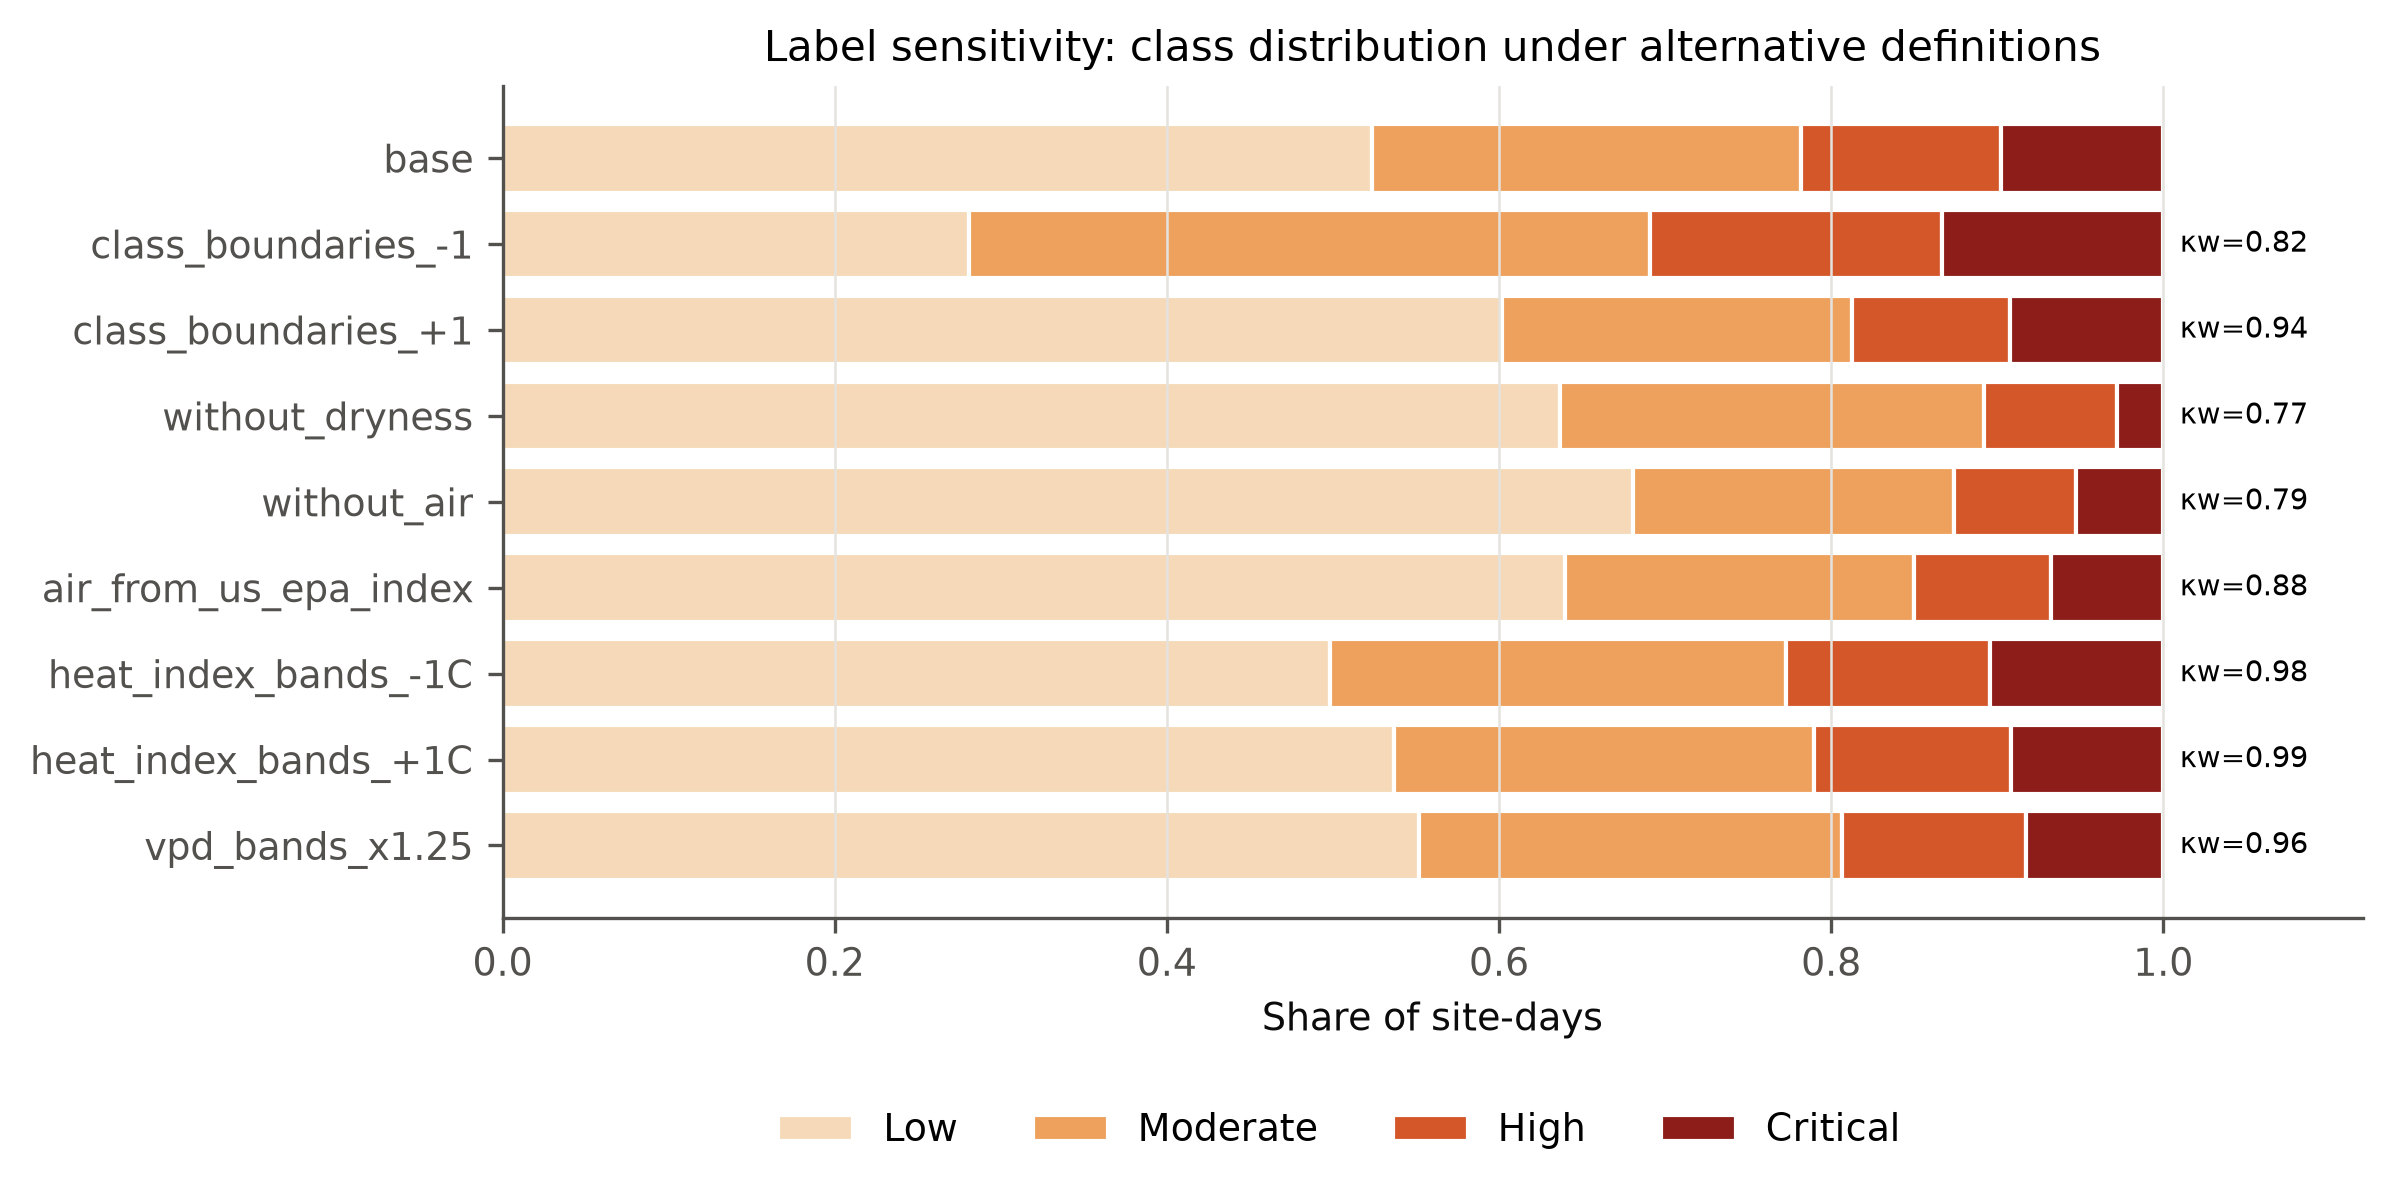

next-day label persistence: 0.756
WHO-based air score vs provider US-EPA index: {'exact_agreement': 0.5146981856245638, 'spearman': 0.6307401318234991}
drivers of High/Critical: {'heat_ge2': 0.494, 'air_ge2': 0.564, 'dryness_ge2': 0.698}


,median_local_hour,share_heat_ge2,share_high_critical,n
"(-180, -90]",6.50,0.042,0.048,4268.0
"(-90, -30]",4.25,0.082,0.028,25192.0
"(-30, 30]",9.75,0.076,0.150,62297.0
"(30, 90]",12.00,0.209,0.369,44418.0
"(90, 180]",17.25,0.453,0.344,24321.0


In [5]:
show("results/figures/labels/label_sensitivity.png")
print("next-day label persistence:", round(ls["next_day_label_persistence"], 3))
print("WHO-based air score vs provider US-EPA index:", ls["air_score_vs_us_epa_index"])
print("drivers of High/Critical:", {k: round(v, 3) for k, v in ls["drivers_high_critical"].items()})
pd.DataFrame(ls["observation_hour_bias_by_longitude"]).T.round(3)

In [6]:
pd.DataFrame(ls["sites_highest_hc_share"])[["location","country","share"]].round(3).head(10)

,location,country,share
0,Riyadh,Saudi Arabia,0.967
1,New Delhi,India,0.952
2,Khartoum,Sudan,0.946
3,Jakarta,Indonesia,0.934
4,Kuwait City,Kuwait,0.912
5,Doha,Qatar,0.888
6,Kuala Lumpur,Malaysia,0.860
7,Muscat,Oman,0.850
8,Manama,Bahrain,0.834
9,Dhaka,Bangladesh,0.830


### Validity concerns
1. **Circularity.** Labels are deterministic functions of observed weather and air quality. The
   task is therefore forecasting a rule-defined state one or more days ahead — not discovery of
   an independent ground truth. Today's label persists to tomorrow on ≈ 76 % of days, so the
   persistence forecast is the reference to beat.
2. **Observation-hour bias** (table above) distorts heat stress by longitude.
3. **No external validation** (EM-DAT not permitted) — classes are internally consistent and
   regionally plausible but not validated against health or disaster outcomes.
4. **Proxy dryness**: VPD and precipitation-occurrence history replace SPEI/soil moisture/NDVI.